# spatial temporal plot

In [39]:
import pandas as pd

In [40]:
sample_w_data_dir = "./data/sample_w_data.csv"
sample_w_data_df = pd.read_csv(sample_w_data_dir)

FileNotFoundError: [Errno 2] No such file or directory: './data/sample_w_data.csv'

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

cal_fire_dir = "./data/California_Historic_Fire_Perimeters_-4891938132824355098.geojson"
cal_fire_gdf = gpd.read_file(cal_fire_dir)
cal_fire_gdf["ALARM_DATE"] = pd.to_datetime(cal_fire_gdf["ALARM_DATE"], utc=True, errors="coerce")

cal_fire_10ys_gdf = cal_fire_gdf[(cal_fire_gdf["ALARM_DATE"].dt.year >= 2015) & (cal_fire_gdf["ALARM_DATE"].dt.year < 2025)]
cal_fire_10ys_gdf["year"] = cal_fire_10ys_gdf["ALARM_DATE"].dt.year
cal_fire_10ys_gdf["month"] = cal_fire_10ys_gdf["ALARM_DATE"].dt.month
cal_fire_10ys_gdf["month_name"] = cal_fire_10ys_gdf["ALARM_DATE"].dt.month_name().str[:3]


NameError: name 'to_crs' is not defined

In [ ]:

cal_fire_10ys_gdf = cal_fire_10ys_gdf.to_crs(epsg=4326)

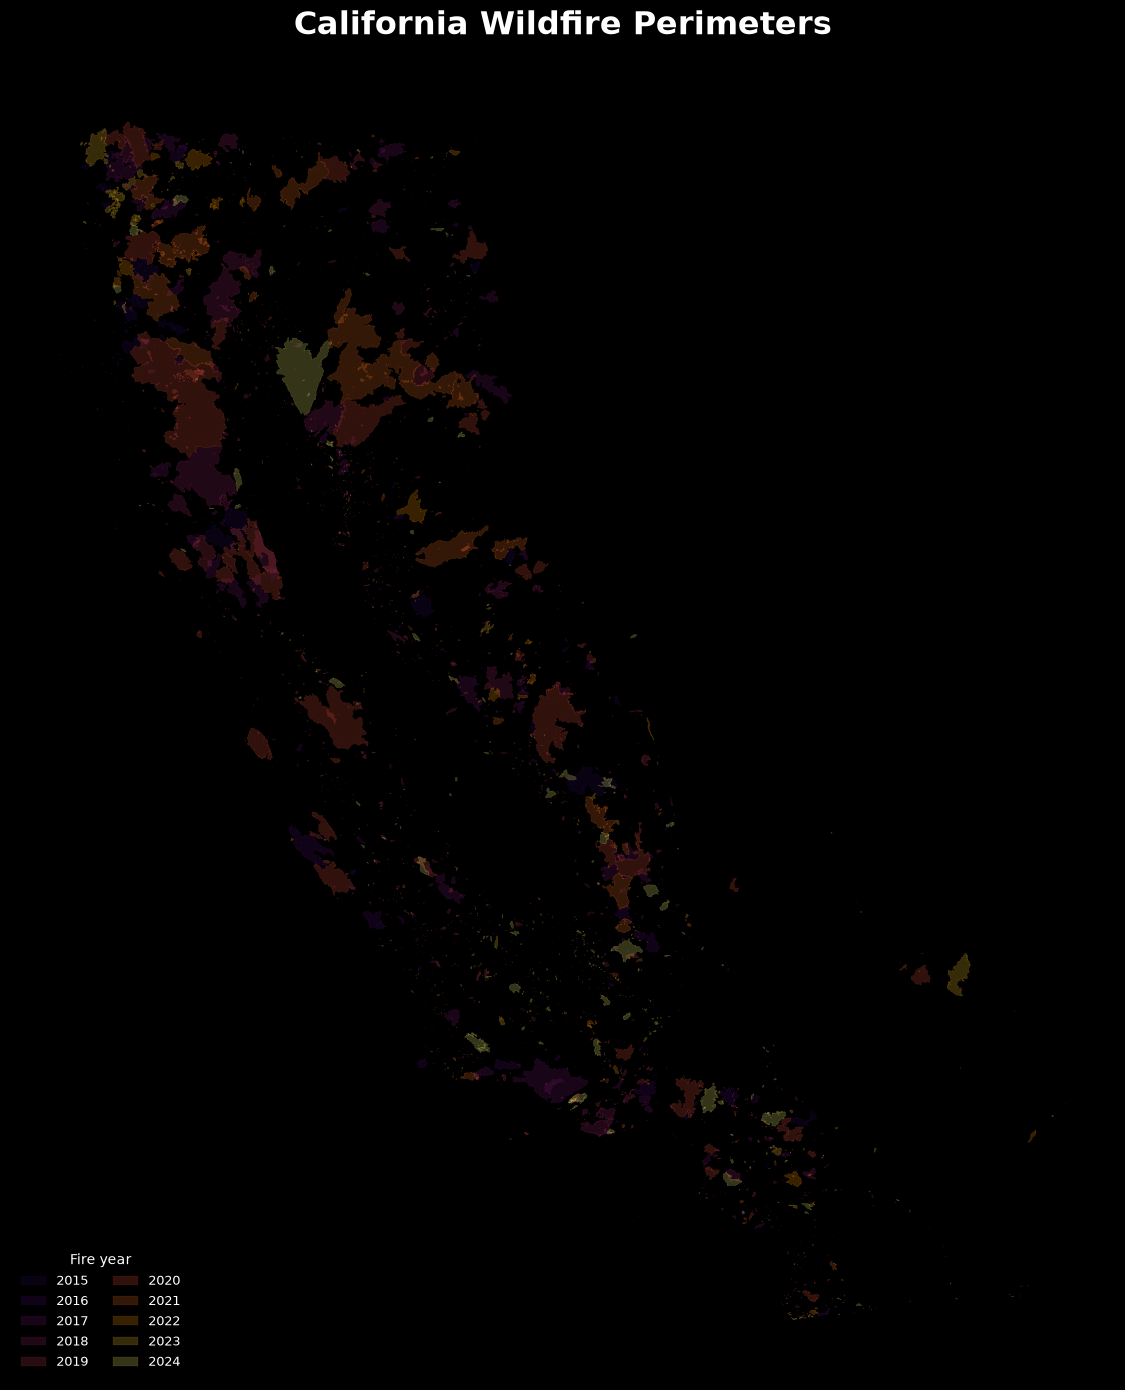

In [ ]:
# # plt.style.use("dark_background")

# fig, ax = plt.subplots(
#     figsize=(12, 14),
#     # facecolor="#101418"
# )

# # ax.set_facecolor("#101418")

# # Color each year using a fire-inspired palette
# years = sorted(cal_fire_10ys_gdf["year"].unique())

# colors = plt.cm.inferno(
#     np.linspace(0.15, 0.95, len(years))
# )

# color_dict = dict(zip(years, colors))

# # Plot each year separately so we can create a legend
# for year in years:

#     subset = cal_fire_10ys_gdf[
#         cal_fire_10ys_gdf["year"] == year
#     ]

#     subset.plot(
#         ax=ax,
#         color=color_dict[year],
#         alpha=0.22,
#         edgecolor=color_dict[year],
#         linewidth=0.25,
#         label=str(year)
#     )

# ax.set_title(
#     "California Wildfire Perimeters",
#     fontsize=23,
#     fontweight="bold",
#     color="white",
#     pad=20
# )

# # ax.text(
# #     0.5,
# #     1.01,
# #     "Historical fire events · 2015–2024",
# #     transform=ax.transAxes,
# #     ha="center",
# #     fontsize=14,
# #     color="#bbbbbb"
# # )

# ax.legend(
#     title="Fire year",
#     loc="lower left",
#     frameon=False,
#     fontsize=9,
#     title_fontsize=10,
#     ncol=2
# )

# ax.axis("off")

# plt.tight_layout()

# # plt.savefig(
# #     "./intermediate_data/california_wildfires_2015_2024_map.png",
# #     dpi=300,
# #     bbox_inches="tight",
# #     facecolor=fig.get_facecolor()
# # )

# plt.show()

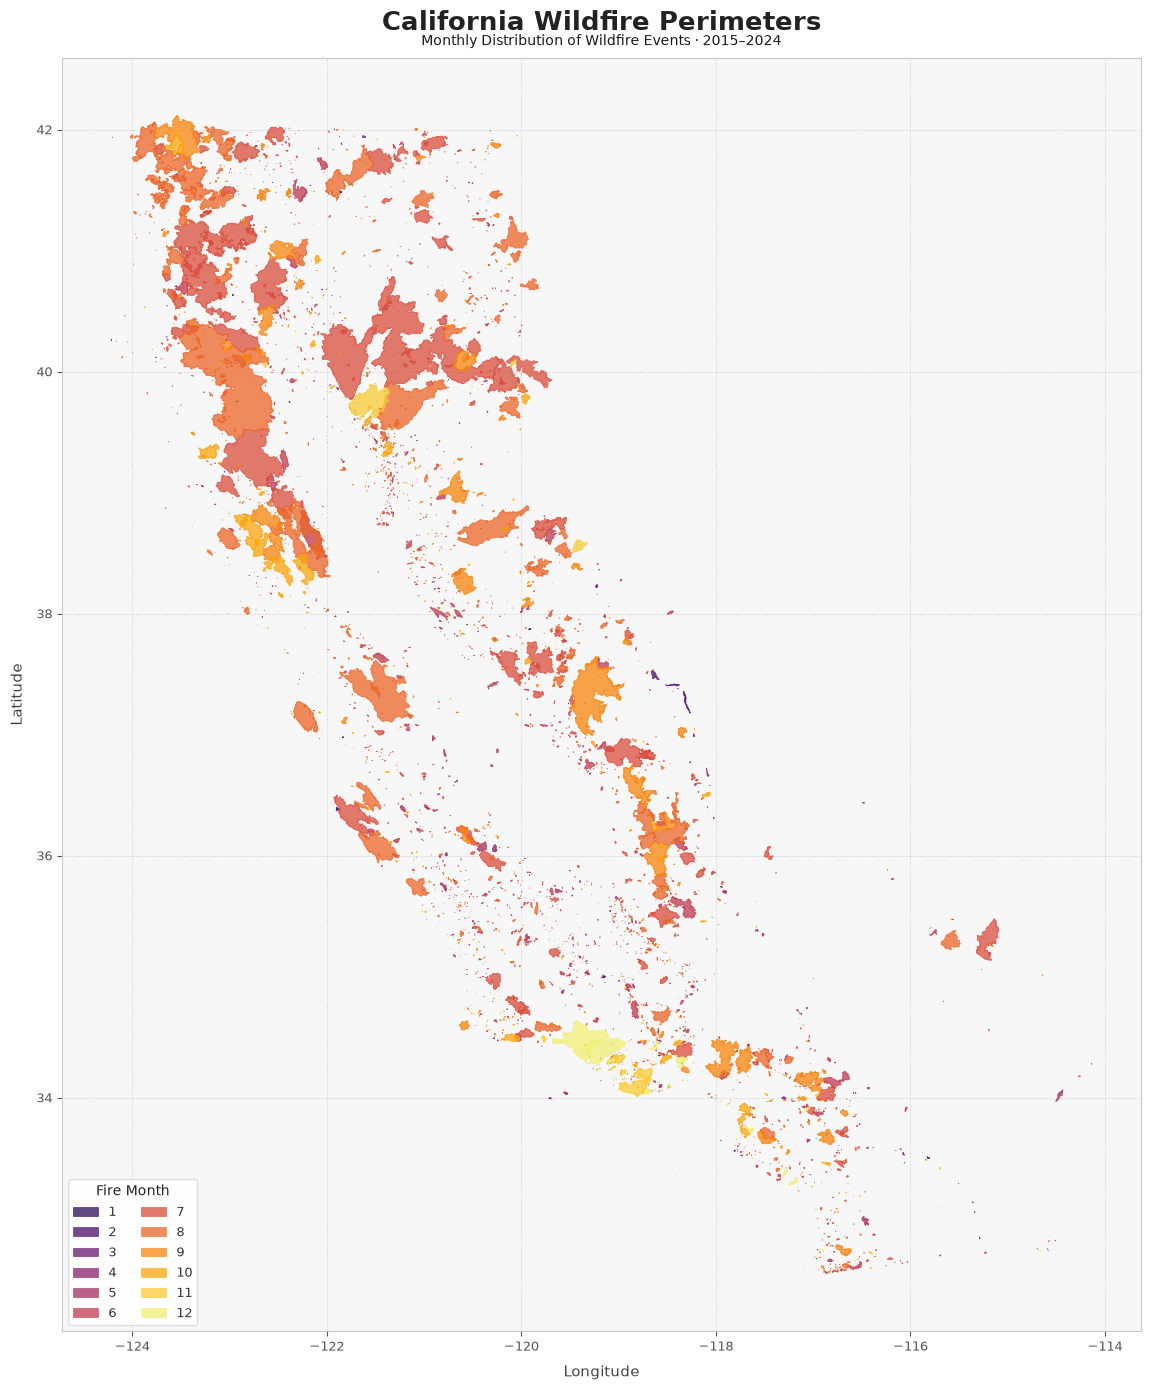

In [ ]:
fig, ax = plt.subplots(
    figsize=(12, 14),
    facecolor="white"
)

ax.set_facecolor("#f7f7f7")


# ============================================================
# Fire colors
# ============================================================

months = sorted(
    cal_fire_10ys_gdf["month"].unique()
)

colors = plt.cm.inferno(
    np.linspace(0.15, 0.95, len(months))
)

color_dict = dict(
    zip(months, colors)
)


# ============================================================
# Plot fire perimeters
# ============================================================

for month in months:

    subset = cal_fire_10ys_gdf[
        cal_fire_10ys_gdf["month"] == month
    ]

    subset.plot(
        ax=ax,
        color=color_dict[month],
        alpha=0.75,              # darker than 0.20
        edgecolor=color_dict[month],
        linewidth=0.5,          # slightly stronger perimeter
        label=str(month)
    )


# ============================================================
# Title
# ============================================================

ax.set_title(
    "California Wildfire Perimeters",
    fontsize=19,
    fontweight="bold",
    color="#222222",
    pad=20
)

ax.text(
    0.5,
    1.01,
    "Monthly Distribution of Wildfire Events · 2015–2024",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="#191818"
)


# ============================================================
# Coordinate grid
# ============================================================

ax.tick_params(
    axis="both",
    which="both",
    labelsize=9,
    colors="#555555",
    labelcolor="#555555"
)

ax.grid(
    True,
    color="#999999",
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)

ax.set_axisbelow(True)


# ============================================================
# Axis labels
# ============================================================

ax.set_xlabel(
    "Longitude",
    fontsize=11,
    color="#444444",
    labelpad=8
)

ax.set_ylabel(
    "Latitude",
    fontsize=11,
    color="#444444",
    labelpad=8
)


# ============================================================
# Spines
# ============================================================

for spine in ax.spines.values():
    spine.set_color("#c8c8c8")
    spine.set_linewidth(0.8)


# ============================================================
# Legend
# ============================================================

legend = ax.legend(
    title="Fire Month",
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="#dddddd",
    framealpha=0.95,
    fontsize=9,
    title_fontsize=10,
    ncol=2
)

# Dark legend text
plt.setp(
    legend.get_texts(),
    color="#333333"
)

plt.setp(
    legend.get_title(),
    color="#222222"
)


# ============================================================
# Final
# ============================================================

plt.tight_layout()

plt.savefig(
    "./intermediate_data/california_wildfires_2015_2024_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


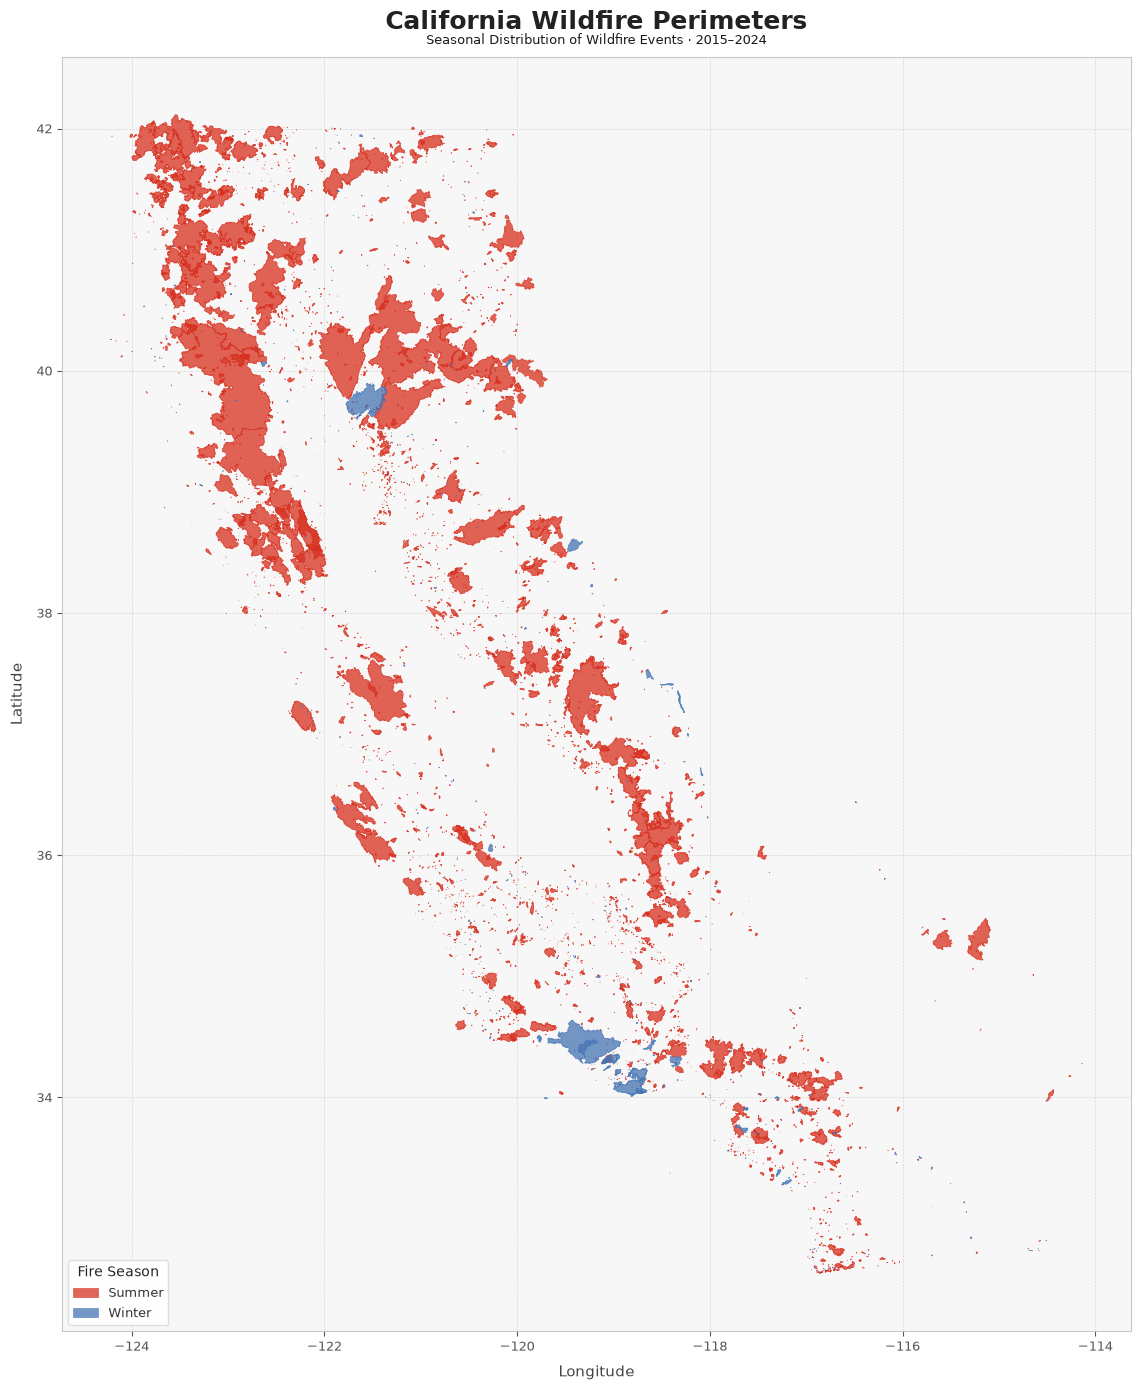

In [ ]:
fig, ax = plt.subplots(
    figsize=(12, 14),
    facecolor="white"
)

ax.set_facecolor("#f7f7f7")


# ============================================================
# Fire seasons
# ============================================================

# May–October = Summer
# November–April = Winter

cal_fire_10ys_gdf["season"] = np.where(
    cal_fire_10ys_gdf["month"].isin([5, 6, 7, 8, 9, 10]),
    "Summer",
    "Winter"
)

seasons = ["Summer", "Winter"]

# Use distinct fire colors for the two seasons
color_dict = {
    "Summer": "#d7301f",   # warm red/orange
    "Winter": "#4575b4"    # cool blue
}


# ============================================================
# Plot fire perimeters
# ============================================================

for season in seasons:

    subset = cal_fire_10ys_gdf[
        cal_fire_10ys_gdf["season"] == season
    ]

    subset.plot(
        ax=ax,
        color=color_dict[season],
        alpha=0.75,
        edgecolor=color_dict[season],
        linewidth=0.5,
        label=season
    )


# ============================================================
# Title
# ============================================================

ax.set_title(
    "California Wildfire Perimeters",
    fontsize=18,
    fontweight="bold",
    color="#222222",
    pad=20
)

ax.text(
    0.5,
    1.01,
    "Seasonal Distribution of Wildfire Events · 2015–2024",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color="#191818"
)


# ============================================================
# Coordinate grid
# ============================================================

ax.tick_params(
    axis="both",
    which="both",
    labelsize=9,
    colors="#555555",
    labelcolor="#555555"
)

ax.grid(
    True,
    color="#999999",
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)

ax.set_axisbelow(True)


# ============================================================
# Axis labels
# ============================================================

ax.set_xlabel(
    "Longitude",
    fontsize=11,
    color="#444444",
    labelpad=8
)

ax.set_ylabel(
    "Latitude",
    fontsize=11,
    color="#444444",
    labelpad=8
)


# ============================================================
# Spines
# ============================================================

for spine in ax.spines.values():
    spine.set_color("#c8c8c8")
    spine.set_linewidth(0.8)


# ============================================================
# Legend
# ============================================================

legend = ax.legend(
    title="Fire Season",
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="#dddddd",
    framealpha=0.95,
    fontsize=9,
    title_fontsize=10
)

plt.setp(
    legend.get_texts(),
    color="#333333"
)

plt.setp(
    legend.get_title(),
    color="#222222"
)


# ============================================================
# Final
# ============================================================

plt.tight_layout()

plt.savefig(
    "./intermediate_data/california_wildfires_2015_2024_seasonal_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [ ]:
month_order = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

monthly_counts = (
    cal_fire_10ys_gdf["month_name"]
    .value_counts()
    .reindex(month_order)
    .fillna(0)
)
monthly_counts

month_name
Jan     46
Feb     46
Mar     50
Apr    124
May    354
Jun    809
Jul    987
Aug    706
Sep    475
Oct    288
Nov    109
Dec     60
Name: count, dtype: int64

In [ ]:
norm = mpl.colors.Normalize(
    vmin=monthly_counts.min(),
    vmax=monthly_counts.max()
)

cmap = plt.cm.YlOrRd

bar_colors = [
    cmap(norm(value))
    for value in monthly_counts.values
]

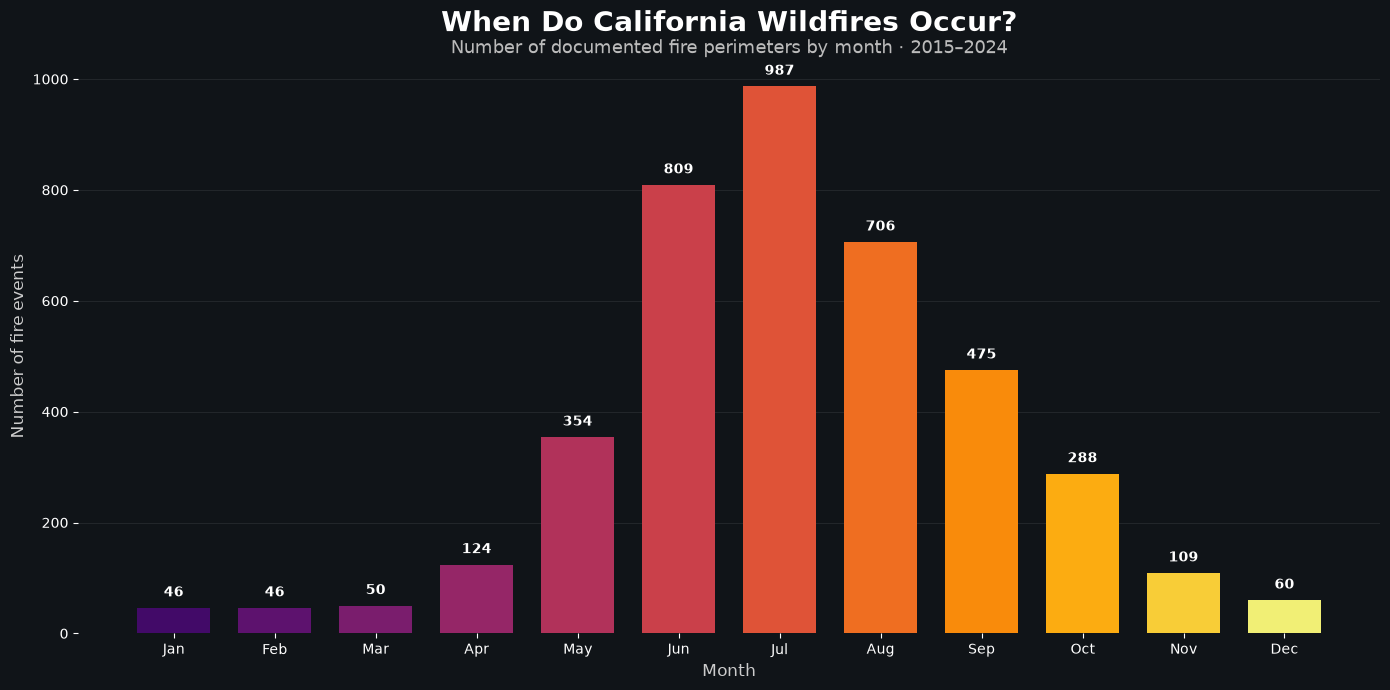

In [ ]:
# fig, ax = plt.subplots(
#     figsize=(14, 7),
#     facecolor="#101418"
# )

# ax.set_facecolor("#101418")

# # Fire-like gradient
# bar_colors = plt.cm.inferno(
#     np.linspace(0.2, 0.95, 12)
# )

# bars = ax.bar(
#     month_order,
#     monthly_counts.values,
#     color=bar_colors,
#     width=0.72
# )

# for bar, value in zip(bars, monthly_counts.values):

#     ax.text(
#         bar.get_x() + bar.get_width() / 2,
#         bar.get_height() + monthly_counts.max() * 0.015,
#         f"{int(value):,}",
#         ha="center",
#         va="bottom",
#         fontsize=10,
#         color="white",
#         fontweight="bold"
#     )


# ax.set_title(
#     "When Do California Wildfires Occur?",
#     fontsize=20,
#     fontweight="bold",
#     color="white",
#     pad=20
# )

# ax.text(
#     0.5,
#     1.01,
#     "Number of documented fire perimeters by month · 2015–2024",
#     transform=ax.transAxes,
#     ha="center",
#     fontsize=13,
#     color="#bbbbbb"
# )

# ax.set_xlabel(
#     "Month",
#     fontsize=12,
#     color="#cccccc"
# )

# ax.set_ylabel(
#     "Number of fire events",
#     fontsize=12,
#     color="#cccccc"
# )

# ax.grid(
#     axis="y",
#     color="white",
#     alpha=0.08
# )

# ax.set_axisbelow(True)

# sns.despine(
#     ax=ax,
#     left=True,
#     bottom=True
# )

# plt.tight_layout()

# # plt.savefig(
# #     "california_wildfires_by_month.png",
# #     dpi=300,
# #     bbox_inches="tight",
# #     facecolor=fig.get_facecolor()
# # )

# plt.show()



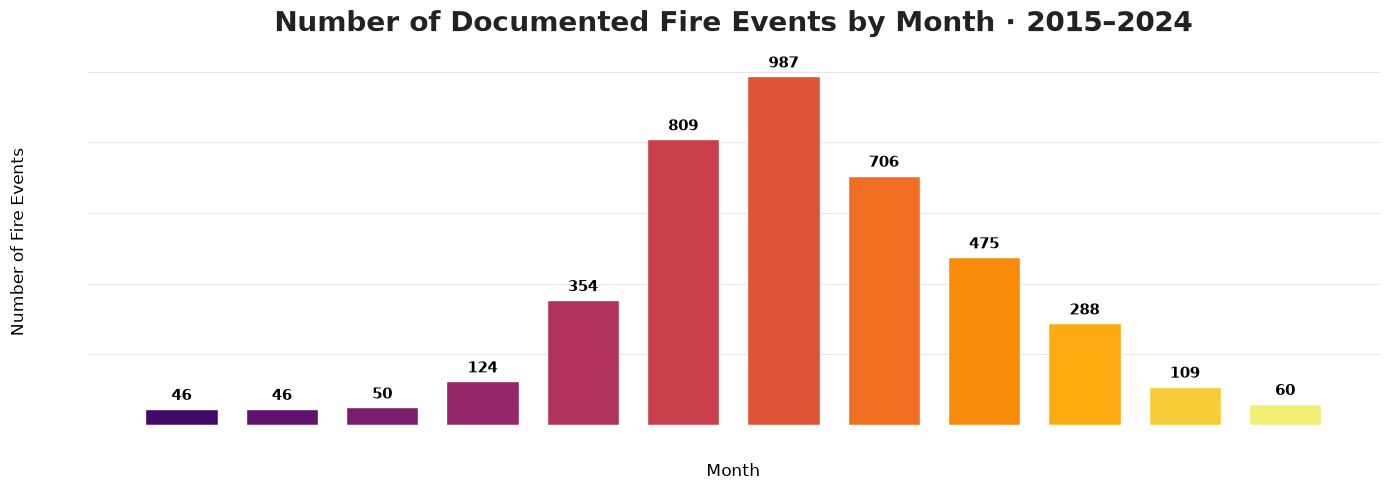

In [ ]:
# fig, ax = plt.subplots(
#     figsize=(14, 4),
#     facecolor="white"
# )

# ax.set_facecolor("white")

# bars = ax.bar(
#     month_order,
#     monthly_counts.values,
#     color=bar_colors,
#     width=0.72,
#     edgecolor="white",
#     linewidth=1
# )


# # ------------------------------------------------------------
# # Values above bars
# # ------------------------------------------------------------

# for bar, value in zip(
#     bars,
#     monthly_counts.values
# ):

#     ax.text(
#         bar.get_x() + bar.get_width() / 2,
#         bar.get_height() + monthly_counts.max() * 0.015,
#         f"{int(value):,}",
#         ha="center",
#         va="bottom",
#         fontsize=11,
#         fontweight="bold",
#         color="#000000"
#     )


# # ------------------------------------------------------------
# # Title
# # ------------------------------------------------------------

# # ax.set_title(
# #     "When Do California Wildfires Occur?",
# #     fontsize=20,
# #     fontweight="bold",
# #     color="#222222",
# #     pad=20
# # )

# ax.set_title(
#     "Number of Documented Fire Events by Month · 2015–2024",
#     fontsize=20,
#     fontweight="bold",
#     color="#222222",
#     pad=20
# )


# # ax.text(
# #     0.5,
# #     1.01,
# #     "Number of documented fire events by month · 2015–2024",
# #     transform=ax.transAxes,
# #     ha="center",
# #     fontsize=13,
# #     color="#666666"
# # )


# # ------------------------------------------------------------
# # Axis labels
# # ------------------------------------------------------------

# ax.set_xlabel(
#     "Month",
#     fontsize=12,
#     color="#000000",
#     labelpad=10
# )

# ax.set_ylabel(
#     "Number of Fire Events",
#     fontsize=12,
#     color="#000000",
#     labelpad=10
# )


# # ------------------------------------------------------------
# # Grid
# # ------------------------------------------------------------

# ax.grid(
#     axis="y",
#     color="#dddddd",
#     linewidth=0.8,
#     alpha=0.7
# )

# ax.set_axisbelow(True)


# # Remove unnecessary borders
# sns.despine(
#     ax=ax,
#     top=True,
#     right=True
# )


# # ------------------------------------------------------------
# # Save
# # ------------------------------------------------------------

# plt.tight_layout()

# plt.savefig(
#     "./intermediate_data/california_wildfires_by_month.png",
#     dpi=300,
#     bbox_inches="tight",
#     facecolor="white"
# )

# plt.show()

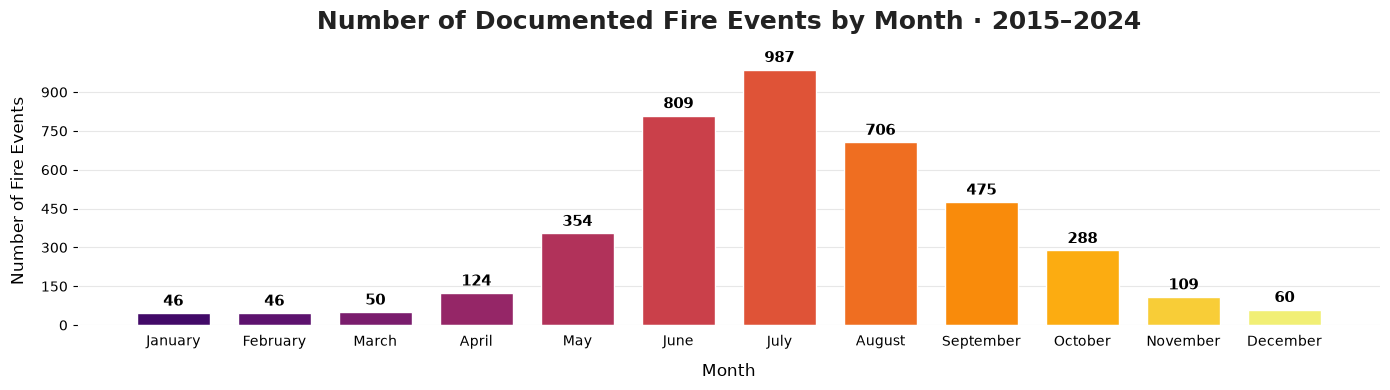

In [ ]:
import matplotlib.ticker as ticker

fig, ax = plt.subplots(
    figsize=(14, 4),
    facecolor="white"
)

ax.set_facecolor("white")


# ============================================================
# Bars
# ============================================================

bars = ax.bar(
    month_order,
    monthly_counts.values,
    color=bar_colors,
    width=0.72,
    edgecolor="white",
    linewidth=1
)


# ============================================================
# Values above bars
# ============================================================

for bar, value in zip(
    bars,
    monthly_counts.values
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + monthly_counts.max() * 0.015,
        f"{int(value):,}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#000000"
    )


# ============================================================
# Title
# ============================================================

ax.set_title(
    "Number of Documented Fire Events by Month · 2015–2024",
    fontsize=18,
    fontweight="bold",
    color="#222222",
    pad=20
)


# ============================================================
# X-axis — full month names
# ============================================================

full_month_names = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

ax.set_xticks(range(len(full_month_names)))
ax.set_xticklabels(
    full_month_names,
    fontsize=10,
    color="#000000"
)

ax.set_xlabel(
    "Month",
    fontsize=12,
    color="#000000",
    labelpad=10
)


# ============================================================
# Y-axis — number of fire events
# ============================================================

ax.set_ylabel(
    "Number of Fire Events",
    fontsize=12,
    color="#000000",
    labelpad=10
)

# Force y-axis to display whole numbers
ax.yaxis.set_major_locator(
    ticker.MaxNLocator(integer=True)
)

ax.tick_params(
    axis="y",
    labelsize=10,
    colors="#000000"
)


# ============================================================
# Grid
# ============================================================

ax.grid(
    axis="y",
    color="#dddddd",
    linewidth=0.8,
    alpha=0.7
)

ax.set_axisbelow(True)


# ============================================================
# Remove unnecessary borders
# ============================================================

sns.despine(
    ax=ax,
    top=True,
    right=True
)


# ============================================================
# Save
# ============================================================

plt.tight_layout()

plt.savefig(
    "./intermediate_data/california_wildfires_by_month.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [ ]:
heatmap_data = pd.crosstab(
    cal_fire_10ys_gdf["year"],
    cal_fire_10ys_gdf["month_name"]
)

heatmap_data = heatmap_data.reindex(
    columns=month_order,
    fill_value=0
)

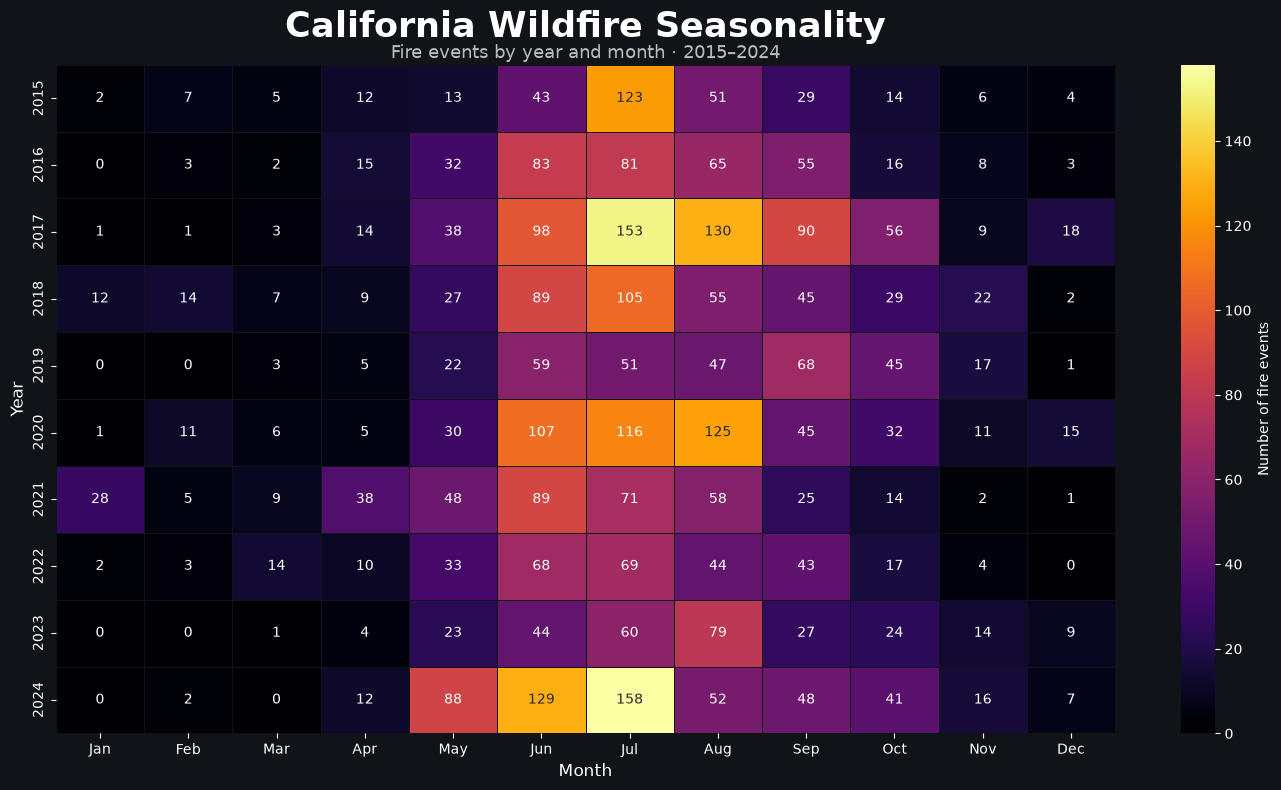

In [ ]:
fig, ax = plt.subplots(
    figsize=(14, 8),
    facecolor="#101418"
)

ax.set_facecolor("#101418")

sns.heatmap(
    heatmap_data,
    cmap="inferno",
    annot=True,
    fmt="d",
    linewidths=0.5,
    linecolor="#101418",
    cbar_kws={
        "label": "Number of fire events"
    },
    ax=ax
)

ax.set_title(
    "California Wildfire Seasonality",
    fontsize=25,
    fontweight="bold",
    color="white",
    pad=20
)

ax.text(
    0.5,
    1.01,
    "Fire events by year and month · 2015–2024",
    transform=ax.transAxes,
    ha="center",
    fontsize=13,
    color="#bbbbbb"
)

ax.set_xlabel(
    "Month",
    fontsize=12
)

ax.set_ylabel(
    "Year",
    fontsize=12
)

plt.tight_layout()

# plt.savefig(
#     "california_wildfire_year_month_heatmap.png",
#     dpi=300,
#     bbox_inches="tight",
#     facecolor=fig.get_facecolor()
# )

plt.show()

# analysis

In [6]:
# pearson correlation
import pandas as pd
# import seaborn as sns

# import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv("./intermediate_data/sample_w_data.csv")
df["ALARM_DATE"] = pd.to_datetime(df["ALARM_DATE"], utc=True, errors="coerce")

variables = [
    "precipitation_sum",
    "temperature_2m_max",
    "wind_speed_10m_max",
    "shortwave_radiation_sum",
    "et0_fao_evapotranspiration",
    "elevation"
]


sum_df  = df[(df["ALARM_DATE"].dt.month >= 5) & (df["ALARM_DATE"].dt.month <= 10)].reset_index()
# sum_df
win_df = df[(df["ALARM_DATE"].dt.month >= 11) | (df["ALARM_DATE"].dt.month <= 4)].reset_index()



Correlation matrix:
                            precipitation_sum  temperature_2m_max  \
precipitation_sum                    1.000000           -0.258569   
temperature_2m_max                  -0.258569            1.000000   
wind_speed_10m_max                  -0.049041           -0.068576   
shortwave_radiation_sum             -0.337436            0.291630   
et0_fao_evapotranspiration          -0.309884            0.684895   
elevation                            0.248596           -0.343543   

                            wind_speed_10m_max  shortwave_radiation_sum  \
precipitation_sum                    -0.049041                -0.337436   
temperature_2m_max                   -0.068576                 0.291630   
wind_speed_10m_max                    1.000000                 0.025269   
shortwave_radiation_sum               0.025269                 1.000000   
et0_fao_evapotranspiration            0.369968                 0.659381   
elevation                            -0.03635

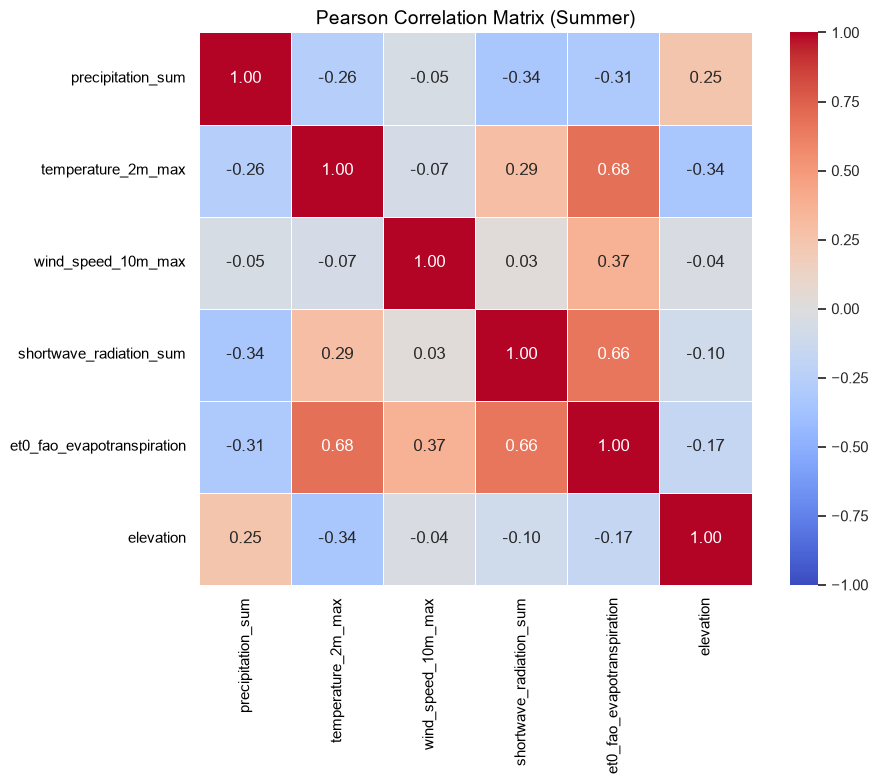

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt



# Correlation matrix
corr_sum = sum_df[variables].corr(method="pearson")

print("\nCorrelation matrix:")
print(corr_sum)

# Plot correlation heatmap
# plt.figure(figsize=(10, 8))

# sns.heatmap(
#     corr,
#     annot=True,
#     cmap="coolwarm",
#     vmin=-1,
#     vmax=1,
#     center=0,
#     fmt=".2f",
#     square=True
# )

# plt.title("Pearson Correlation Matrix")
# plt.tight_layout()
# plt.show()
sns.set_theme(style="white")

plt.figure(figsize=(10, 8), facecolor="white")

ax = sns.heatmap(
    corr_sum,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    linecolor="white"
)

ax.set_facecolor("white")

plt.title(
    "Pearson Correlation Matrix (Summer)",
    color="black",
    fontsize=14
)

plt.xticks(color="black")
plt.yticks(color="black")

plt.tight_layout()
plt.savefig("./intermediate_data/pearson_correlation_matrix_sum.png",
        dpi=300,
        bbox_inches="tight")
plt.show()



Correlation matrix:
                            precipitation_sum  temperature_2m_max  \
precipitation_sum                    1.000000           -0.178499   
temperature_2m_max                  -0.178499            1.000000   
wind_speed_10m_max                   0.037507           -0.028000   
shortwave_radiation_sum             -0.149763            0.398719   
et0_fao_evapotranspiration          -0.157965            0.654322   
elevation                            0.118928           -0.486769   

                            wind_speed_10m_max  shortwave_radiation_sum  \
precipitation_sum                     0.037507                -0.149763   
temperature_2m_max                   -0.028000                 0.398719   
wind_speed_10m_max                    1.000000                -0.010074   
shortwave_radiation_sum              -0.010074                 1.000000   
et0_fao_evapotranspiration            0.393993                 0.693128   
elevation                            -0.05620

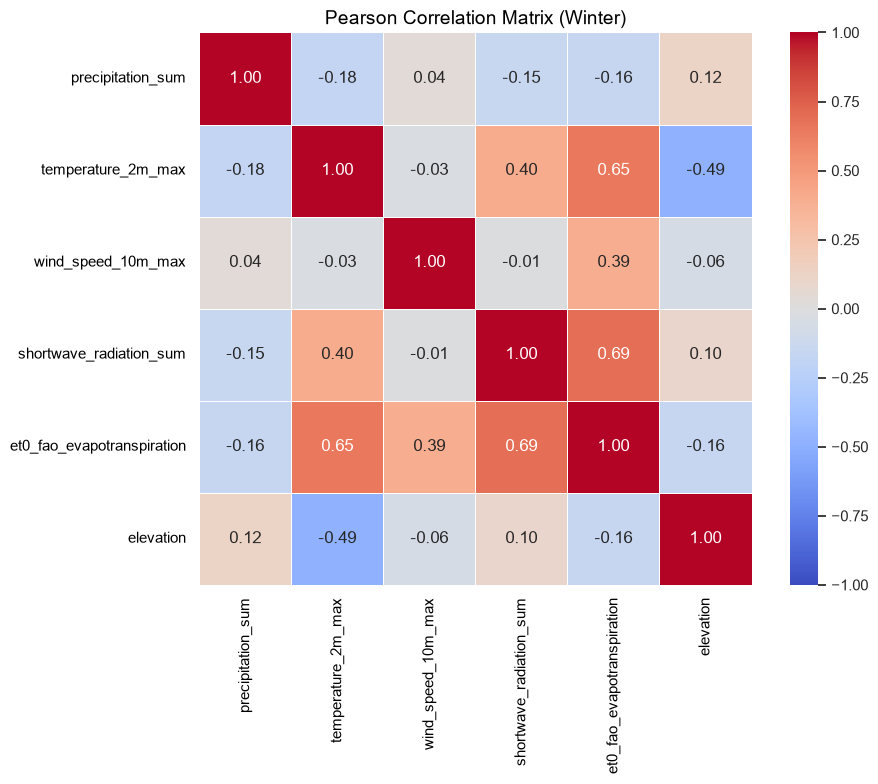

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt



# Correlation matrix
corr_win = win_df[variables].corr(method="pearson")

print("\nCorrelation matrix:")
print(corr_win)

# Plot correlation heatmap
# plt.figure(figsize=(10, 8))

# sns.heatmap(
#     corr,
#     annot=True,
#     cmap="coolwarm",
#     vmin=-1,
#     vmax=1,
#     center=0,
#     fmt=".2f",
#     square=True
# )

# plt.title("Pearson Correlation Matrix")
# plt.tight_layout()
# plt.show()
sns.set_theme(style="white")

plt.figure(figsize=(10, 8), facecolor="white")

ax = sns.heatmap(
    corr_win,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    linecolor="white"
)

ax.set_facecolor("white")

plt.title(
    "Pearson Correlation Matrix (Winter)",
    color="black",
    fontsize=14
)

plt.xticks(color="black")
plt.yticks(color="black")

plt.tight_layout()
plt.savefig("./intermediate_data/pearson_correlation_matrix_win.png",
        dpi=300,
        bbox_inches="tight")
plt.show()


In [ ]:
# p-values
import pandas as pd
from scipy.stats import pearsonr

df = pd.read_csv("./intermediate_data/sample_w_data.csv")

variables = [
    "precipitation_sum",
    "temperature_2m_max",
    "wind_speed_10m_max",
    "shortwave_radiation_sum",
    "et0_fao_evapotranspiration",
    "elevation"
]

for i in range(len(variables)):
    for j in range(i + 1, len(variables)):

        x = df[variables[i]]
        y = df[variables[j]]

        # Remove missing values
        valid = x.notna() & y.notna()

        r, p = pearsonr(x[valid], y[valid])

        print(
            f"{variables[i]} vs {variables[j]}: "
            f"r = {r:.3f}, p = {p:.4e}"
        )


precipitation_sum vs temperature_2m_max: r = -0.167, p = 2.5867e-07
precipitation_sum vs wind_speed_10m_max: r = 0.004, p = 8.9757e-01
precipitation_sum vs shortwave_radiation_sum: r = -0.180, p = 3.0909e-08
precipitation_sum vs et0_fao_evapotranspiration: r = -0.185, p = 1.3106e-08
precipitation_sum vs elevation: r = 0.182, p = 2.1634e-08
temperature_2m_max vs wind_speed_10m_max: r = -0.109, p = 8.0750e-04
temperature_2m_max vs shortwave_radiation_sum: r = 0.612, p = 3.3102e-97
temperature_2m_max vs et0_fao_evapotranspiration: r = 0.804, p = 1.7169e-212
temperature_2m_max vs elevation: r = -0.192, p = 3.1215e-09
wind_speed_10m_max vs shortwave_radiation_sum: r = -0.069, p = 3.5250e-02
wind_speed_10m_max vs et0_fao_evapotranspiration: r = 0.226, p = 3.0249e-12
wind_speed_10m_max vs elevation: r = -0.061, p = 6.3541e-02
shortwave_radiation_sum vs et0_fao_evapotranspiration: r = 0.799, p = 5.2774e-208
shortwave_radiation_sum vs elevation: r = 0.094, p = 4.1822e-03
et0_fao_evapotranspirat

|r|	Interpretation

0–0.19	Very weak

0.20–0.39	Weak

0.40–0.59	Moderate

0.60–0.79	Strong

0.80–1.00	Very strong

# Moran I

In [11]:
import pandas as pd
import numpy as np
from libpysal.weights import KNN
from esda.moran import Moran

# --- 1. Load data ---
df = pd.read_csv("./intermediate_data/sample_w_data.csv", parse_dates=["ALARM_DATE"])

variables = [
    "precipitation_sum",
    "temperature_2m_max",
    "wind_speed_10m_max",
    "shortwave_radiation_sum",
    "et0_fao_evapotranspiration",
    # "elevation",
]

df = df.dropna(subset=["longitude", "latitude"] + variables).reset_index(drop=True)

sum_df  = df[(df["ALARM_DATE"].dt.month >= 5) & (df["ALARM_DATE"].dt.month <= 10)].reset_index()
# sum_df
win_df = df[(df["ALARM_DATE"].dt.month >= 11) | (df["ALARM_DATE"].dt.month <= 4)].reset_index()



In [18]:
# summer
# --- 2. Build spatial weights matrix once (same coords for all variables) ---
coords = sum_df[["longitude", "latitude"]].values
w = KNN.from_array(coords, k=7)   # tune k based on point density / study area
w.transform = "r"

# --- 3. Compute Moran's I for each variable ---
results = []
for var in variables:
    mi = Moran(sum_df[var].values, w, permutations=999)
    results.append({
        "variable": var,
        "I": mi.I,
        "expected_I": mi.EI,
        "p_sim": mi.p_sim,
        "z_sim": mi.z_sim,
        "significant": mi.p_sim < 0.05
    })

results_sum_df = pd.DataFrame(results).sort_values("I", ascending=False)
print(results_sum_df.to_string(index=False))

                  variable        I  expected_I  p_sim    z_sim  significant
        wind_speed_10m_max 0.216491   -0.002004  0.001 9.982397         True
        temperature_2m_max 0.208604   -0.002004  0.001 9.041627         True
et0_fao_evapotranspiration 0.169447   -0.002004  0.001 7.658572         True
         precipitation_sum 0.038905   -0.002004  0.044 2.207632         True
   shortwave_radiation_sum 0.027154   -0.002004  0.108 1.293917        False


In [ ]:
#winter
# --- 2. Build spatial weights matrix once (same coords for all variables) ---
coords = win_df[["longitude", "latitude"]].values
w = KNN.from_array(coords, k=300)   # tune k based on point density / study area
w.transform = "r"

# --- 3. Compute Moran's I for each variable ---
results = []
for var in variables:
    mi = Moran(win_df[var].values, w, permutations=999)
    results.append({
        "variable": var,
        "I": mi.I,
        "expected_I": mi.EI,
        "p_sim": mi.p_sim,
        "z_sim": mi.z_sim,
        "significant": mi.p_sim < 0.05
    })

results_win_df = pd.DataFrame(results).sort_values("I", ascending=False)
print(results_win_df.to_string(index=False))

                  variable         I  expected_I  p_sim     z_sim  significant
        temperature_2m_max  0.075995   -0.002304  0.001 54.921835         True
et0_fao_evapotranspiration  0.024313   -0.002304  0.001 17.027716         True
        wind_speed_10m_max -0.000539   -0.002304  0.123  1.127846        False
         precipitation_sum -0.002069   -0.002304  0.301  0.193639        False
   shortwave_radiation_sum -0.003415   -0.002304  0.208 -0.717163        False


,index,Unnamed: 0,ALARM_DATE,longitude,latitude,precipitation_sum,temperature_2m_max,wind_speed_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration,elevation
0,0,0,2024-11-06,-119.022686,34.315834,0.0,20.0,33.9,15.04,4.53,358.0
1,1,1,2024-12-09,-118.697780,34.051584,0.0,17.5,7.2,10.97,1.63,167.0
2,2,2,2024-04-27,-119.395926,35.785077,0.3,24.9,21.0,21.98,4.54,67.0
3,3,3,2024-04-12,-119.397845,35.160027,0.0,31.9,32.9,25.84,6.14,256.0
4,4,4,2024-11-29,-117.483697,34.026599,0.0,20.6,17.3,7.47,3.11,343.0
...,...,...,...,...,...,...,...,...,...,...,...
430,430,430,2015-04-27,-118.596061,34.079639,0.0,29.6,17.2,28.56,6.27,253.0
431,431,431,2015-11-07,-118.795922,34.083639,0.0,23.0,16.6,15.71,4.31,548.0
432,432,432,2015-12-25,-119.226845,34.287208,0.0,12.8,25.9,12.03,2.40,159.0
433,433,433,2015-02-09,-119.362328,34.384812,0.0,22.1,9.2,15.74,2.64,223.0


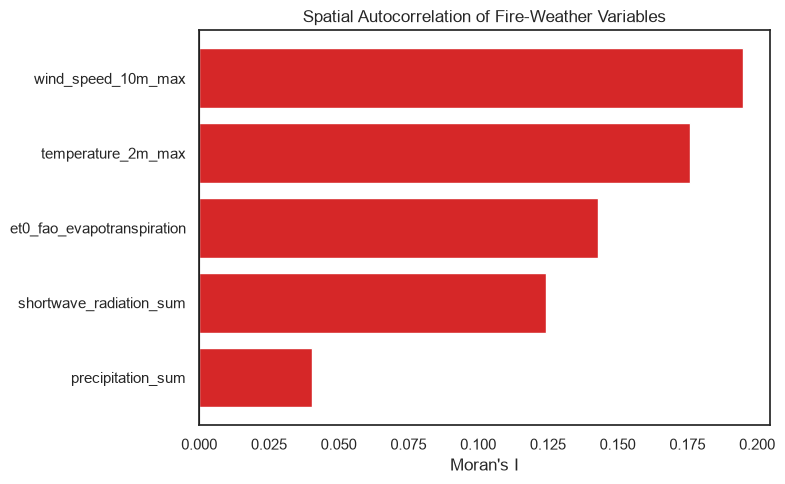

c:\Users\84348\ai4hws-project\.venv\Lib\site-packages\splot\_viz_esda_mpl.py:131: UserWarning: `p` is only used for plotting `esda.moran.Moran_Local`
or `Moran_Local_BV` objects
  warnings.warn(
c:\Users\84348\ai4hws-project\.venv\Lib\site-packages\spreg\diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)
c:\Users\84348\ai4hws-project\.venv\Lib\site-packages\splot\_viz_esda_mpl.py:131: UserWarning: `p` is only used for plotting `esda.moran.Moran_Local`
or `Moran_Local_BV` objects
  warnings.warn(
c:\Users\84348\ai4hws-project\.venv\Lib\site-packages\spreg\diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)
c:\Users\84348\ai4hws-project\.venv\Lib\site-packages\splot\_viz_esda_mpl.py:131: UserWarning: `p` is only used for plotting `esda.moran.Moran_Local`
or `Moran_Local_BV` objects
  warnings.warn(
c:\Users\84348\ai

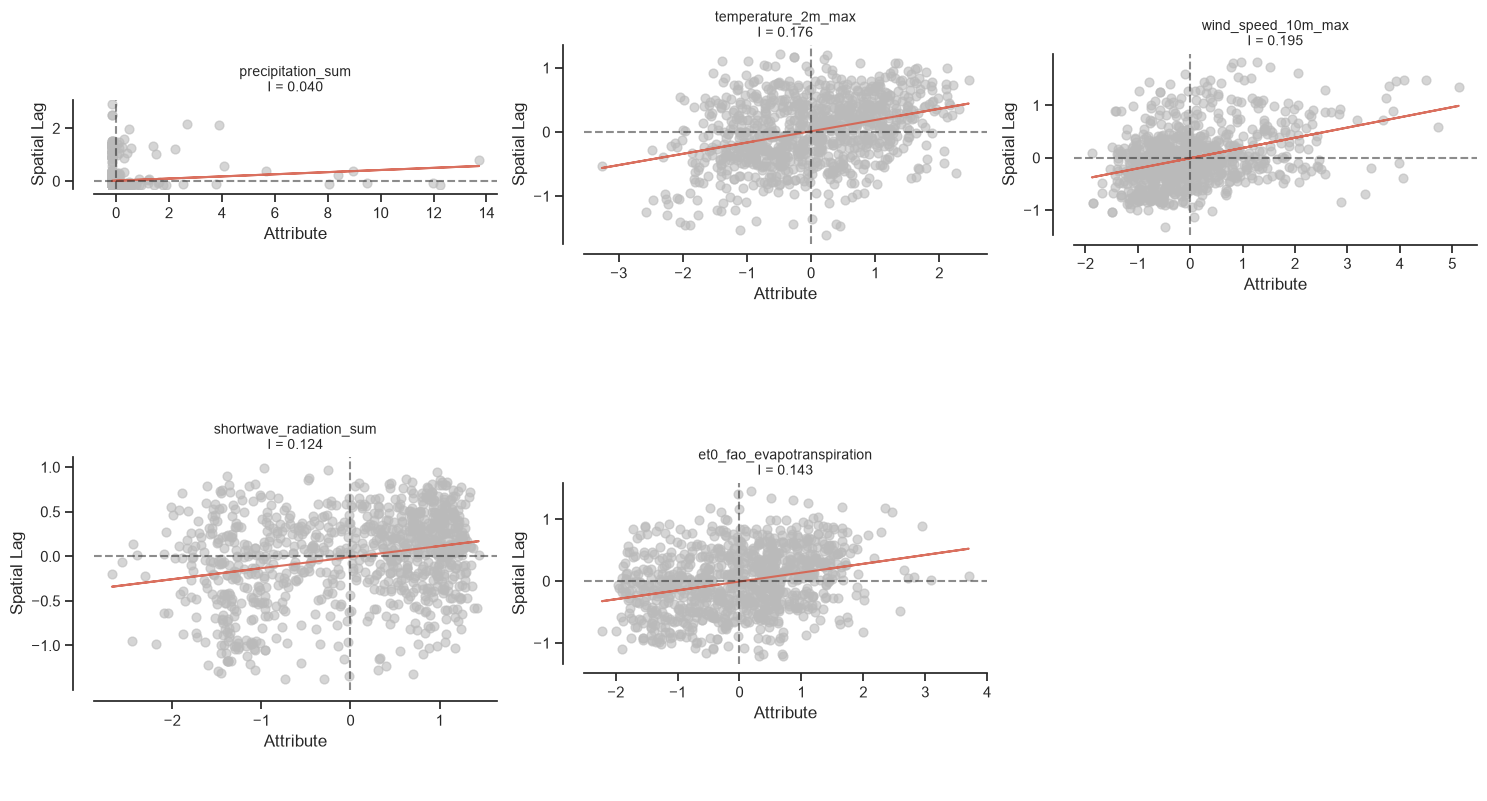

In [10]:
import matplotlib.pyplot as plt
from esda.moran import Moran
from libpysal.weights import KNN
from splot.esda import moran_scatterplot

# --- Bar chart comparing I values ---
fig, ax = plt.subplots(figsize=(8, 5))
results_df_sorted = results_df.sort_values("I", ascending=True)
colors = ["#d62728" if sig else "#7f7f7f" for sig in results_df_sorted["significant"]]

ax.barh(results_df_sorted["variable"], results_df_sorted["I"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Moran's I")
ax.set_title("Spatial Autocorrelation of Fire-Weather Variables")
plt.tight_layout()
plt.savefig("moran_bar_chart.png", dpi=150)
plt.show()

# --- Moran scatterplots (one per variable) ---
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, var in enumerate(variables):
    mi = Moran(df[var].values, w, permutations=999)
    moran_scatterplot(mi, ax=axes[i], zstandard=True, p=0.05)
    axes[i].set_title(f"{var}\nI = {mi.I:.3f}", fontsize=10)

# hide unused subplot (6th slot, since you have 5 variables)
axes[-1].axis("off")

plt.tight_layout()
# plt.savefig("moran_scatterplots.png", dpi=150)
plt.show()